In [ ]:
#Create a virtual SLM and camera
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
import matplotlib.pyplot as plt
import numpy as np
wav_um = 1.064
slm_shape = (1024, 1280) # (give height, width)
cam_shape = (1080,1440) # (give height, width)
slm = SimulatedSLM((slm_shape[1], slm_shape[0]), pitch_um=(8, 8), wav_um=wav_um) #(width,height)
slm.set_source_analytic(sim=True,x0 =  0, y0 = 0, a =  1, c = 0,wx = 4000,wy = 4000)
cam = SimulatedCamera(slm,(cam_shape[1], cam_shape[0]), pitch_um=(3.45,3.45)) #(width,height)
# The setup (a FourierSLM setup with a camera placed in the Fourier plane of an SLM) holds the camera and SLM.
# Tie the camera and SLM together with an analytic calibration.
fs = FourierSLM(cam, slm)
M, b = fs.fourier_calibration_build(
    f_eff=60000.,                              # f_eff of 80000 wavelengths or 80 mm with the default 1 um wavelength
    theta=5 * np.pi / 180,
)
cam.set_affine(M, b)
fs.fourier_calibrate_analytic(M, b)


{'M': array([[24578.57759466, -2150.34690512],
        [ 2150.34690512, 24578.57759466]]),
 'b': array([[720.],
        [540.]]),
 'a': array([[0],
        [0]]),
 '__version__': '0.2.1',
 '__time__': '2025-08-26 00:53:05.492413',
 '__timestamp__': 1756187585.492413,
 '__meta__': {'__class__': '<slmsuite.hardware.cameraslms.FourierSLM object at 0x16e9c9f90>',
  'name': 'camera-SLM',
  'cam': {'__class__': '<slmsuite.hardware.cameras.simulated.SimulatedCamera object at 0x16e9ca350>',
   'name': 'camera',
   'shape': (1080, 1440),
   'bitdepth': 8,
   'bitresolution': 256,
   'pitch_um': array([3.45, 3.45]),
   'exposure_s': 1,
   'exposure_bounds_s': None,
   'averaging': None,
   'hdr': None,
   'woi': (0, 1440, 0, 1080),
   'default_shape': (1080, 1440)},
  'slm': {'__class__': '<slmsuite.hardware.slms.simulated.SimulatedSLM object at 0x16e9c91d0>',
   'name': 'SLM',
   'shape': (1024, 1280),
   'bitdepth': 8,
   'bitresolution': 256,
   'pitch_um': array([8., 8.]),
   'pitch': array(

/var/folders/py/_lrzt4sd23jgrnhmp_01ng8h0000gn/T/ipykernel_37678/3308555471.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  (int(center[0] - res[0]/2), int(center[0] + res[0]/2)),
/var/folders/py/_lrzt4sd23jgrnhmp_01ng8h0000gn/T/ipykernel_37678/3308555471.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  (int(center[1] - res[1]/2), int(center[1] + res[1]/2))


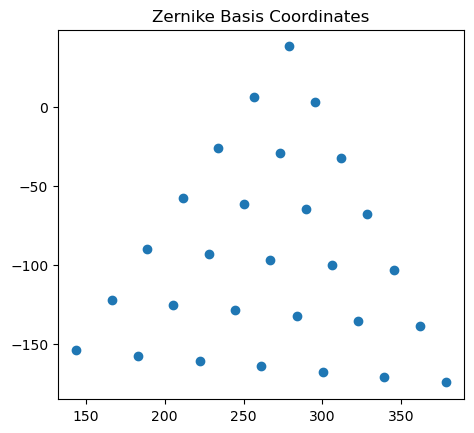

In [68]:
from slmsuite.holography.toolbox import format_vectors
from slmsuite.holography.toolbox.phase import zernike_convert_index
from slmsuite.holography.toolbox import convert_vector

center = format_vectors((1000, 500))
res = (320, 320)
((i0, i1), (i2, i3)) = limits = (
    (int(center[0] - res[0]/2), int(center[0] + res[0]/2)),
    (int(center[1] - res[1]/2), int(center[1] + res[1]/2))
)

N = 28
i = np.arange(N)
nl = zernike_convert_index(i, from_index="ansi", to_index="radial")
ij = 20 * np.vstack((nl[:, 1], (3-nl[:, 0]) * np.sqrt(3))) + center
sz = convert_vector(ij, from_units="ij", to_units="zernike", hardware=fs)

plt.title("Zernike Basis Coordinates")
plt.scatter(sz[0], sz[1])
plt.gca().set_aspect("equal")

base = np.zeros((N,N))

base[2, :] = sz[0]      # Tilt x term
base[1, :] = sz[1]      # Tilt y term

In [ ]:
perturbation = np.diag(np.ones(N))
print((base + 10*perturbation)[:10, :10].astype(int))

TypeError: ufunc 'bitwise_xor' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [280]:
zernike_calibrations = []
for j in range(N):
    zernike_calibrations.append({i: v.item() for i, v in enumerate((base+ 2*perturbation).T[j])})


In [281]:
from slmsuite.holography.toolbox.phase import zernike_sum
import numpy as np
import torch
class CompressedHolo:
    def __init__(self,zernike_calibrations,H,W):
        """Pass a zernike calibration a list of dicts with keys zernike_index and weights"""
        self.zernike_calibrations = zernike_calibrations
        self.N = len(zernike_calibrations)
        self.H = H
        self.W = W
        self.kernel = self.compute_kernel(zernike_calibrations)
        self.A_in = torch.ones(H,W)/np.sqrt(H*W)
    def zt(self,F_in):
        """zernike transform of the nearfield to farfield 
        Takes input the nearfield and outputs a array of size N
        NxHxW,HxW to Nx1
        """
        return torch.einsum('nhw,hw->n', self.kernel, F_in)
    def izt(self,F_out):
        """inverse zernike transform of the farfield to nearfield 
        Takes input the farfield spot array complex amplitudes and outputs a array of size HxW
        NxHxW,Nx1 to HxW
        """
        return torch.einsum('nhw,n->hw', torch.conj(self.kernel), F_out)
    def compute_kernel(self,zernike_calibrations):
        """Compute the zernike kernel"""
        kernels = []
        for zernike_calibration in zernike_calibrations:
            kernels.append(zernike_sum(fs,tuple(zernike_calibration.keys()),tuple(zernike_calibration.values()),use_mask = False))
        return torch.exp(1j*torch.from_numpy(np.stack(kernels)).float())
    def optimize_gs(self,initial_phase,iters = 10):
        """Optimize the Gerchberg-Saxton algorithm using the zernike transform"""
        if initial_phase == None:
            initial_phase = torch.zeros(self.H,self.W)
        else :
            initial_phase = torch.tensor(initial_phase)
        phi_in = initial_phase
        for iter in range(iters):
            F_in = self.A_in*torch.exp(1j*phi_in)
            phi_out = torch.angle(self.zt(F_in))
            F_out = torch.exp(1j*phi_out)/np.sqrt(self.N)
            phi_in = torch.angle(self.izt(F_out))
        return phi_in.numpy()
    def lens(self,z):
        """ create a lens phase with a quadratic phase near focus
        Args:
            z (float): Propagation distance.
            Returns: lens (torch.Tensor): Lens phase, shape (H, W)"""
        
        return torch.exp(1j * z * self.q_tensor)
    def forward_propagate(self,F_in,z=0):
        """ forward propagation of the field F_in through a lens with a quadratic phase near focus
        Args:
            F_in (torch.Tensor): Input field, shape (H, W).
            z (float): Propagation distance.
            Returns: farfield (torch.Tensor): Output field after propagation, shape (H, W)"""
        if z == 0:
            field_nf = F_in
        else:
            field_nf = F_in * self.lens(z)
        return torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(field_nf), norm='ortho'))
    

In [282]:
cholo = CompressedHolo(zernike_calibrations=zernike_calibrations,H=1024,W=1280)

In [292]:
phase = cholo.optimize_gs(initial_phase=None,iters = 30)

In [293]:
fs.slm.set_phase(phase)

array([[ 33,  50,  75, ...,  68, 110,  96],
       [ 10,   1,  93, ...,  56,  89, 131],
       [215, 106,  34, ...,  69,  68, 120],
       ...,
       [111, 117, 144, ..., 218, 229,   1],
       [ 90, 122, 131, ..., 195, 225, 238],
       [ 82, 114, 137, ..., 193, 206, 229]],
      shape=(1024, 1280), dtype=uint8)

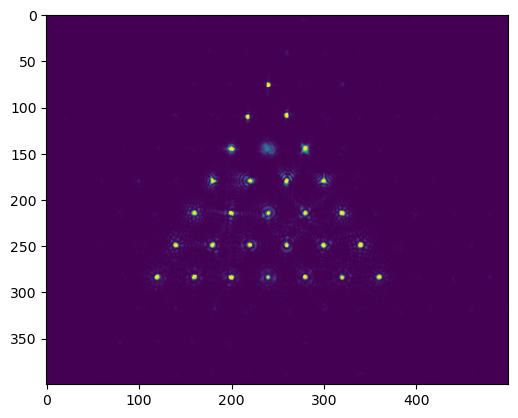

In [294]:
image = fs.cam.get_image()
plt.imshow(image[400:800,200:700])

In [168]:
from src.gradient import SLMphaseRetrievalCG,build_input,build_pbb_target

In [169]:
A_input = build_input()
m = SLMphaseRetrievalCG(A_in = A_input,A_t = None,pad_factor=1)

/Users/apple/Desktop/holography/src/gradient.py:128: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A_in = self.pad(torch.tensor(A_in / FeedbackHologram._norm(A_in), dtype=torch.float32))


/var/folders/py/_lrzt4sd23jgrnhmp_01ng8h0000gn/T/ipykernel_37678/2528688720.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  plt.imshow(m.forward_propagate(m.pad(tensor=A_input)*m.pad(tensor=torch.exp(1j*torch.tensor(phase)))).abs())


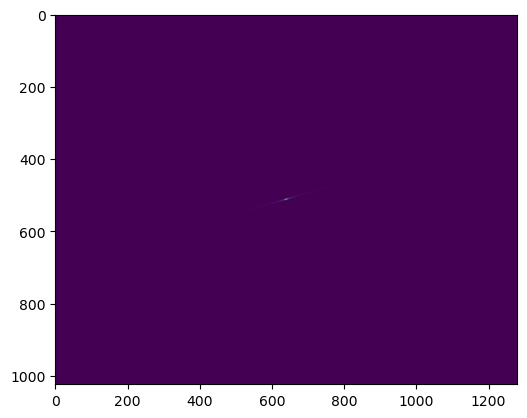

In [170]:
plt.imshow(m.forward_propagate(m.pad(tensor=A_input)*m.pad(tensor=torch.exp(1j*torch.tensor(phase)))).abs())

In [171]:
zernike_calibrations[0].keys()

dict_keys([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27])

In [172]:
tuple(zernike_calibrations[0].values())

(10.0,
 38.50481710325402,
 278.9181375977161,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0)

In [ ]:
phi_in = read phase
for i in range(4):
    calibs = zernike_calib(phi_in)
    cholo = CompressedHolo(zernike_calibrations=calibs,H=1024,W=1280)
    phi_in = cholo.optimize_gs(initial_phase=phi_in,iters = 10)
